In [5]:
from src.model import RigParameters, RigSolver, DistanceCalculator

RIG = {
    "reach_left":        45.5,
    "reach_right":       46.3,
    "arm_height_left":   83.7,
    "arm_height_right":  83.5,
    "joint_height":     125.5,
    "pole_length":       84.5,
    "arm_half_angle":    45.0,
}

In [14]:
# ── enter one (range_left, range_right) pair per can ───────────
can_ranges = [
    (87, 87.6),   # can 0
    (89.5, 92),   # can 1
  # (115.0, 100.0),   # can 2  ← uncomment to add a third can
]
# ───────────────────────────────────────────────────────────────

In [15]:
positions = []
for i, (rL, rR) in enumerate(can_ranges):
    result = RigSolver(
        RigParameters.from_rig
        (RIG, rL, rR)).solve()

    positions.append((result['x'], result['y']))

    print(f"Can {i} : x={result['x']:.1f} cm,  y={result['y']:.1f} cm")
    for w in result['warnings']:
        print(f"  WARNING : {w}")

print()
calc = DistanceCalculator(*positions)

for label, dist in calc.all_distances().items():
    print(f"{label} : {dist:.1f} cm")

Can 0 : x=4.2 cm,  y=450.2 cm
Can 1 : x=15.0 cm,  y=349.6 cm

post -> can 0 : 450.2 cm
post -> can 1 : 349.9 cm
can 0 -> can 1 : 95.9 cm


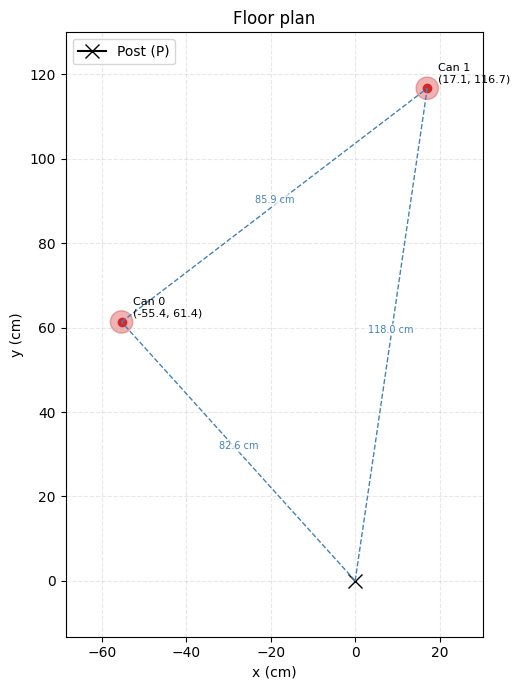

In [8]:
from src.visualise import FloorPlot

FloorPlot(positions).show()